# Tarea 4: Pronóstico de Generación Hidroeléctrica con Redes Neuronales Recurrentes (LSTM)

**Autores:** Jossely Mendoza, Jefferson Olalla, Juan Asimbaya & Juan Coronel  
**Problema:** Predicción multivariable a 24 horas vista (*Day-Ahead Forecasting*) de la central hidroeléctrica Paute-Molino  
**Conjunto de datos:** CELEC EP (Complejo Hidroeléctrico Paute y Minas San Francisco, Ecuador - Dataset EDADES)  
**Técnica:** Redes Recurrentes LSTM (Single LSTM vs Stacked LSTM) con ventanas deslizantes (*Sliding Windows*)


## 1. Configuración de Entorno e Importación de Librerías


In [1]:
# Dependencias principales
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento y métricas
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Deep Learning con TensorFlow / Keras (Arquitecturas LSTM)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Configuración de reproducibilidad y estilos
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 10


## 2. Carga y Normalización del Conjunto de Datos
Se cargan los registros horarios de generación eléctrica y unidades operativas de las centrales hidroeléctricas administradas por CELEC EP:
* **Paute-Molino** (Variable objetivo: central base del sistema nacional)
* **Mazar** (Embalse regulador aguas arriba en la cuenca del Paute)
* **Sopladora** (Central aguas abajo de Molino)
* **Minas San Francisco** (Cuenca Jubones)


In [2]:
DATA_PATH = './data/datos_celec_v1.csv' if os.path.exists('./data/datos_celec_v1.csv') else '/content/datos_celec_v1.csv'

# Carga de datos
df = pd.read_csv(DATA_PATH)

# Saneamiento de nombres de columnas (eliminar caracteres no imprimibles y espacios)
df.columns = [c.replace('\xad', '').strip() for c in df.columns]

# Conversión y ordenamiento cronológico
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df = df.sort_values('Timestamp').reset_index(drop=True)

print(f"Dimensiones del dataset: {df.shape[0]} registros horarios, {df.shape[1]} columnas.")
print(f"Rango temporal: desde {df['Timestamp'].min()} hasta {df['Timestamp'].max()}")
print(f"Total valores nulos: {df.isnull().sum().sum()}")
df.head()


Dimensiones del dataset: 11136 registros horarios, 9 columnas.
Rango temporal: desde 2024-01-01 01:00:00 hasta 2025-04-09 00:00:00
Total valores nulos: 0


,Timestamp,Energía_Molino,Energía_Mazar,Energía_Sopladora,Energía_Minas_San_Francisco,Unidades_Molino,Unidades_Mazar,Unidades_Sopladora,Unidades_Minas_San_Francisco
0,2024-01-01 01:00:00,271.743420,0.0,162.304304,272.00,4,0,1,3
1,2024-01-01 02:00:00,271.321353,0.0,157.102239,272.25,4,0,1,3
2,2024-01-01 03:00:00,253.509839,0.0,153.176297,271.38,4,0,1,3
3,2024-01-01 04:00:00,184.495683,0.0,109.630119,272.25,3,0,1,3
4,2024-01-01 05:00:00,186.025423,0.0,106.103861,271.50,3,0,1,3


## 3. Análisis Exploratorio de Datos (EDA)


In [3]:
# Resumen estadístico de las variables continuas y operativas
resumen = df.describe().T[['mean', 'std', 'min', '50%', 'max']]
resumen.round(2)


,mean,std,min,50%,max
Timestamp,2024-08-20 00:30:00,NaN,2024-01-01 01:00:00,2024-08-20 00:30:00,2025-04-09 00:00:00
Energía_Molino,447.885673,294.549008,0.0,451.091865,1114.359284
Energía_Mazar,54.954352,63.060847,0.0,21.01283,170.963946
Energía_Sopladora,233.358171,141.398903,0.0,261.208371,456.340451
Energía_Minas_San_Francisco,107.636503,103.463516,0.0,69.185,275.13
Unidades_Molino,6.299749,3.334643,0.0,7.0,10.0
Unidades_Mazar,0.818247,0.862538,0.0,1.0,2.0
Unidades_Sopladora,1.765535,0.987247,0.0,2.0,3.0
Unidades_Minas_San_Francisco,1.971624,1.110873,0.0,2.0,3.0


### Diagnóstico estadístico inicial
* **Paute-Molino:** Media de 447.89 MWh con desviación estándar de 294.55 MWh y rango entre 0.00 y 1,114.36 MWh. El coeficiente de variación es del 65.8%, lo que evidencia una dispersión amplia producto de la modulación diaria del despacho y los periodos de estiaje.
* **Unidades en servicio:** Molino opera en promedio con 6.30 unidades activas (máximo 10). Sopladora promedia 1.77 unidades (máximo 3) y Mazar 0.82 unidades (máximo 2).
* **Continuidad del registro:** No existen registros nulos ni saltos temporales a lo largo de las 11,136 horas consecutivas analizadas.


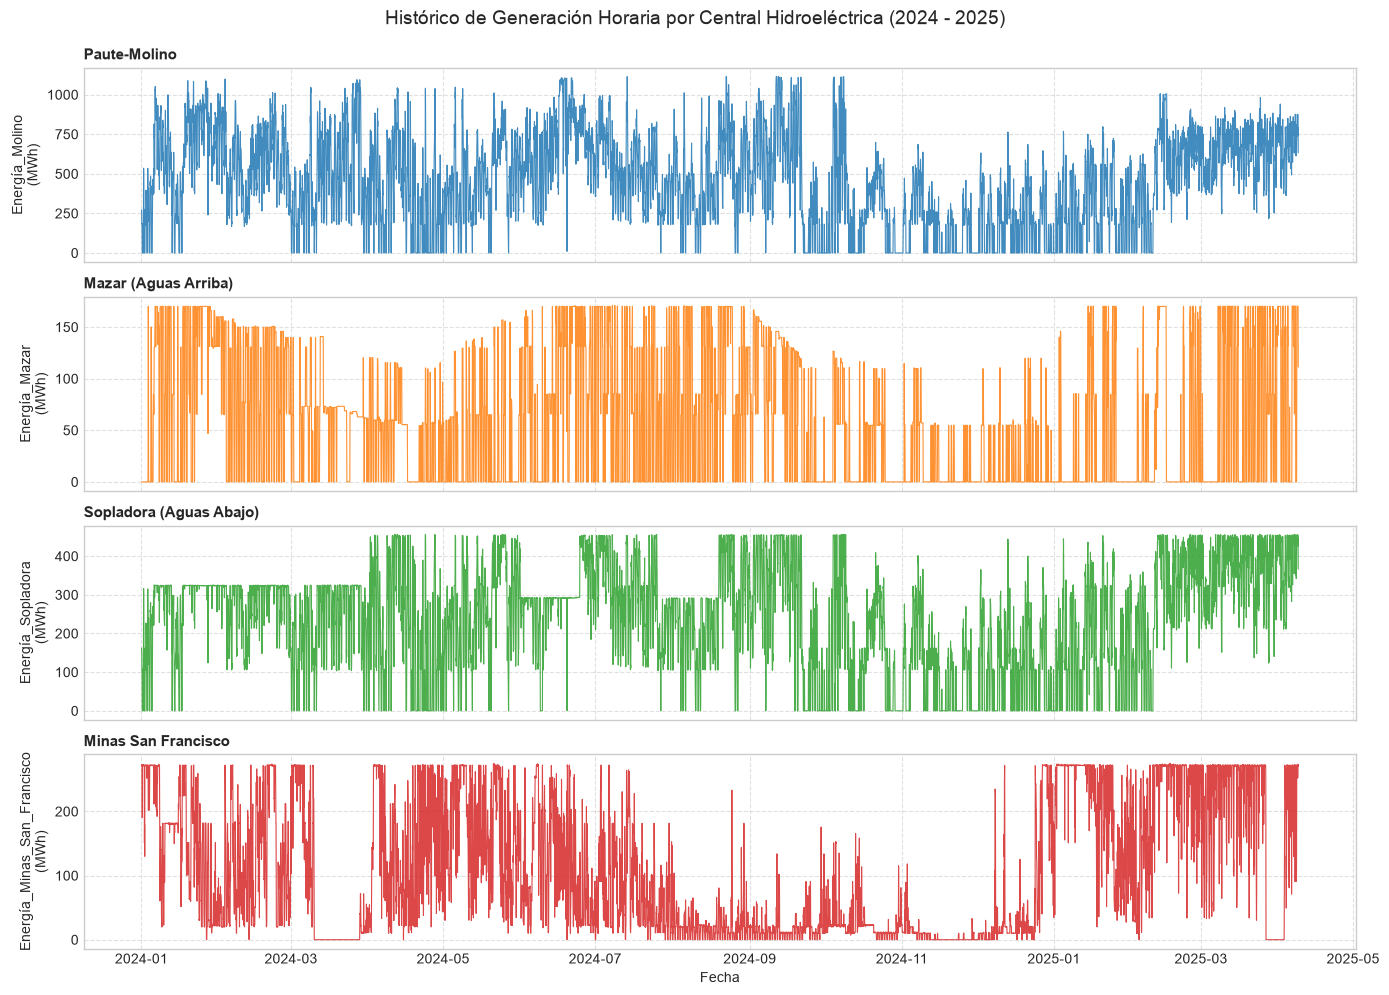

In [4]:
# Visualización de la serie temporal continua de generación
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

centrales = [
    ('Energía_Molino', 'Paute-Molino', '#1f77b4'),
    ('Energía_Mazar', 'Mazar (Aguas Arriba)', '#ff7f0e'),
    ('Energía_Sopladora', 'Sopladora (Aguas Abajo)', '#2ca02c'),
    ('Energía_Minas_San_Francisco', 'Minas San Francisco', '#d62728')
]

for ax, (col, title, color) in zip(axes, centrales):
    ax.plot(df['Timestamp'], df[col], color=color, linewidth=0.8, alpha=0.85)
    ax.set_ylabel(f'{col}\n(MWh)')
    ax.set_title(title, loc='left', fontweight='bold', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.6)

axes[-1].set_xlabel('Fecha')
plt.suptitle('Histórico de Generación Horaria por Central Hidroeléctrica (2024 - 2025)', fontsize=14, y=0.99)
plt.tight_layout()
plt.show()


### Dinámica temporal y estiaje
* **Periodo de estiaje (septiembre - noviembre 2024):** La serie muestra una caída prolongada en la generación de Molino, Sopladora y Mazar, con periodos recurrentes cercanos a 0 MWh (se registran 1,572 horas con menos de 1 MWh en Molino en todo el conjunto). A partir de diciembre de 2024 y durante los primeros meses de 2025 se observa una recuperación paulatina hacia valores medios.
* **Acoplamiento hidráulico:** Las curvas horarias de Paute-Molino y Sopladora se mueven casi en paralelo durante todo el registro, en concordancia con la configuración hidráulica en cascada donde Sopladora aprovecha directamente las descargas turbinadas por Molino.


Pico diario      : Hora 20:00 con 586.55 MWh
Valle diario     : Hora 5:00 con 269.63 MWh
Amplitud diaria  : 316.92 MWh (+117.5%)
Promedio laboral : 468.53 MWh (Lun - Vie)
Promedio domingo : 345.55 MWh (reducción del 26.2%)


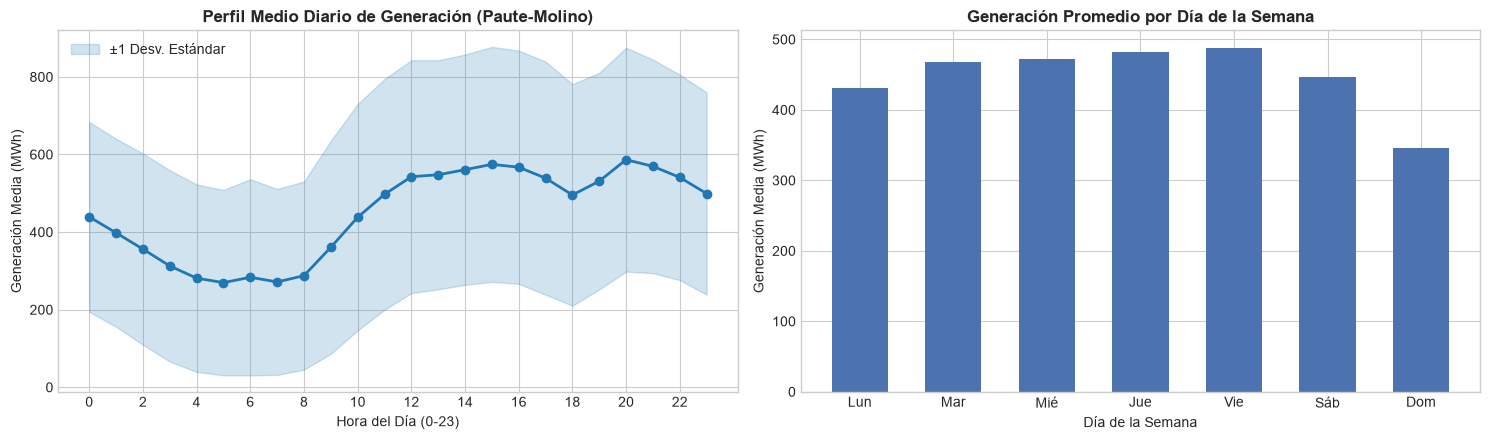

In [5]:
# Análisis cuantitativo de estacionalidad horaria y semanal en Paute-Molino
df['Hora'] = df['Timestamp'].dt.hour
df['DiaSemana'] = df['Timestamp'].dt.day_name()
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

perfil_horario = df.groupby('Hora')['Energía_Molino'].agg(['mean', 'std']).reset_index()
perfil_semanal = df.groupby('DiaSemana')['Energía_Molino'].mean().reindex(dias_orden)

# Cálculo de métricas puntuales para verificación
pico_hora = perfil_horario.loc[perfil_horario['mean'].idxmax(), 'Hora']
pico_val = perfil_horario['mean'].max()
valle_hora = perfil_horario.loc[perfil_horario['mean'].idxmin(), 'Hora']
valle_val = perfil_horario['mean'].min()
prom_laboral = perfil_semanal.loc[['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']].mean()
prom_domingo = perfil_semanal.loc['Sunday']

print(f"Pico diario      : Hora {pico_hora}:00 con {pico_val:.2f} MWh")
print(f"Valle diario     : Hora {valle_hora}:00 con {valle_val:.2f} MWh")
print(f"Amplitud diaria  : {pico_val - valle_val:.2f} MWh (+{((pico_val/valle_val)-1)*100:.1f}%)")
print(f"Promedio laboral : {prom_laboral:.2f} MWh (Lun - Vie)")
print(f"Promedio domingo : {prom_domingo:.2f} MWh (reducción del {((1 - prom_domingo/prom_laboral)*100):.1f}%)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))

ax1.plot(perfil_horario['Hora'], perfil_horario['mean'], color='#1f77b4', marker='o', linewidth=2)
ax1.fill_between(perfil_horario['Hora'],
                 perfil_horario['mean'] - perfil_horario['std'],
                 perfil_horario['mean'] + perfil_horario['std'],
                 color='#1f77b4', alpha=0.2, label='±1 Desv. Estándar')
ax1.set_title('Perfil Medio Diario de Generación (Paute-Molino)', fontweight='bold')
ax1.set_xlabel('Hora del Día (0-23)')
ax1.set_ylabel('Generación Media (MWh)')
ax1.set_xticks(range(0, 24, 2))
ax1.legend()

ax2.bar(range(7), perfil_semanal.values, color='#4c72b0', width=0.6)
ax2.set_title('Generación Promedio por Día de la Semana', fontweight='bold')
ax2.set_xlabel('Día de la Semana')
ax2.set_ylabel('Generación Media (MWh)')
ax2.set_xticks(range(7))
ax2.set_xticklabels(['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'])

plt.tight_layout()
plt.show()


### Estacionalidades horaria y semanal
* **Ciclo diario (24 horas):**
  * **Pico:** Ocurre a las 20:00 con una media de 586.55 MWh (el intervalo 19:00–21:00 supera los 560 MWh).
  * **Valle:** Se registra a las 05:00 con 269.63 MWh.
  * **Amplitud:** La diferencia media pico-valle es de 316.92 MWh (+117.5% sobre el valle), mostrando una marcada curva de carga vespertina.
* **Ciclo semanal (7 días):**
  * De lunes a viernes la generación promedio oscila entre 431.73 y 488.26 MWh (media laboral de 468.53 MWh).
  * El domingo la generación cae a 345.55 MWh (un 26.2% menos que el promedio laboral), producto de la menor demanda en la red nacional durante fines de semana.


Correlación de Pearson frente a Energía_Molino:
                              Energía_Molino
Energía_Molino                         1.000
Energía_Mazar                          0.622
Energía_Sopladora                      0.928
Energía_Minas_San_Francisco            0.187
Unidades_Molino                        0.906
Unidades_Mazar                         0.593
Unidades_Sopladora                     0.842
Unidades_Minas_San_Francisco           0.178


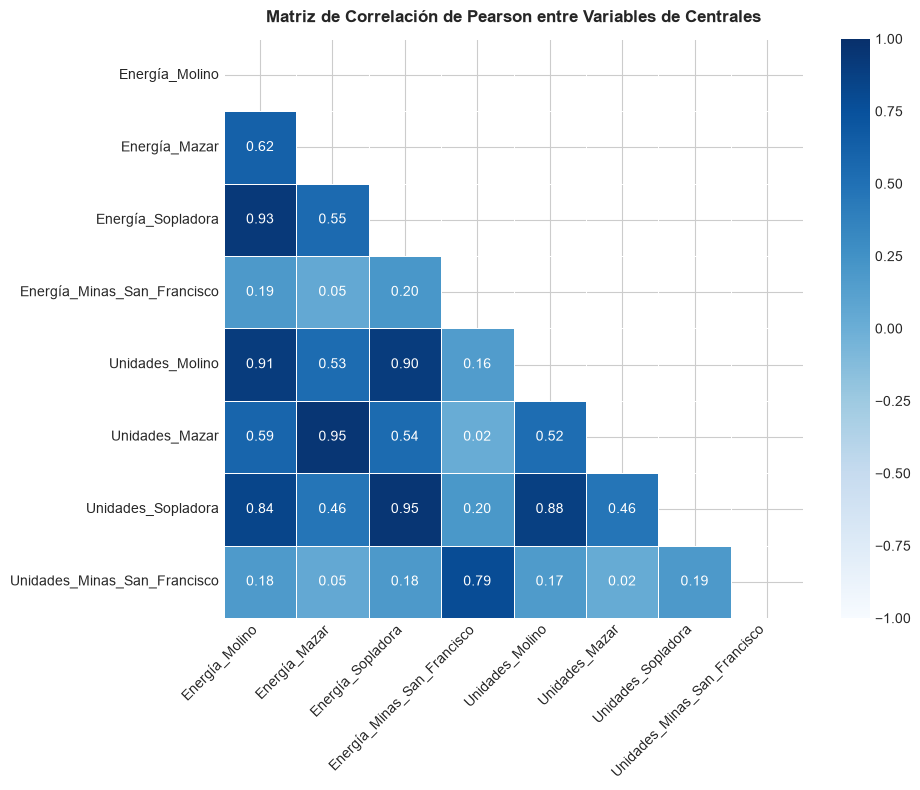

In [6]:
# Matriz de correlación de Pearson
cols_analisis = [c for c in df.columns if c.startswith('Energía_') or c.startswith('Unidades_')]
corr = df[cols_analisis].corr()

# Impresión de coeficientes directos frente a la variable objetivo
print("Correlación de Pearson frente a Energía_Molino:")
print(corr[['Energía_Molino']].round(3))

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='Blues', vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Matriz de Correlación de Pearson entre Variables de Centrales', fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### Relación entre centrales y unidades de operación
* **Molino vs Sopladora ($r = 0.93$):** Correlación lineal muy alta, acorde a la disposición en cascada en la cuenca del Paute.
* **Molino vs Unidades Molino ($r = 0.91$):** Fuerte relación lineal, ya que la potencia despachada depende directamente del número de turbinas sincronizadas.
* **Molino vs Mazar ($r = 0.62$):** Correlación positiva moderada-fuerte; Mazar actúa como embalse de regulación estacional aguas arriba.
* **Minas San Francisco vs Molino ($r = 0.19$):** Correlación débil, consistente con su ubicación en una cuenca hidrográfica independiente (río Jubones hacia el Pacífico).


Correlación Cruzada Mazar(t) vs Molino(t + lag):
Lag 0  : 0.622 (máximo)
Lag 1h : 0.614
Lag 2h : 0.592
Lag 3h : 0.562

Autocorrelación de Energía_Molino en lags clave:
Lag   1 horas: r = 0.967
Lag  24 horas: r = 0.742
Lag  48 horas: r = 0.618
Lag  72 horas: r = 0.569
Lag 168 horas: r = 0.521


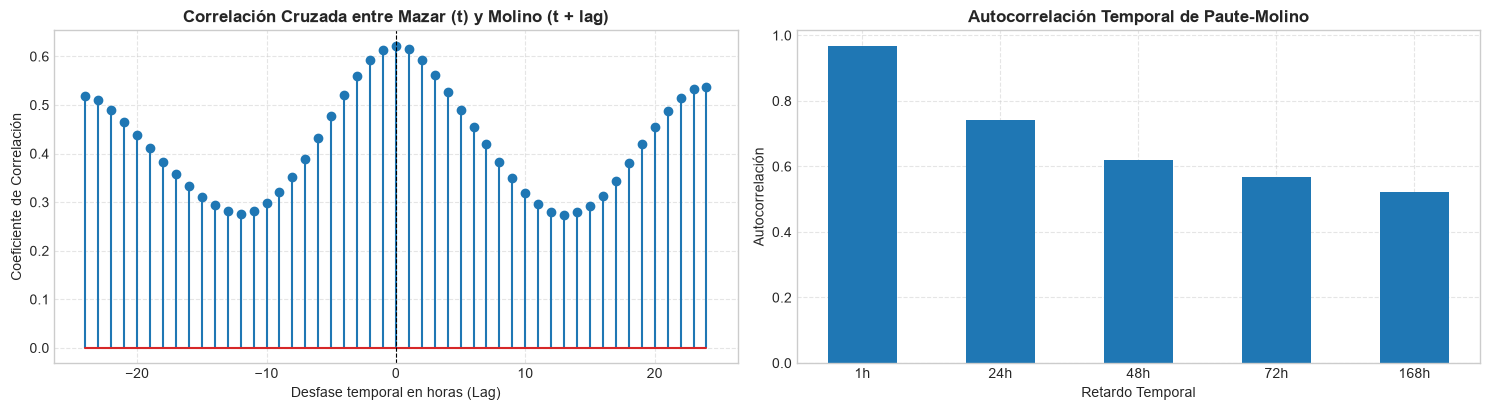

In [7]:
# Análisis de Correlación Cruzada (Mazar vs Molino) y Autocorrelación Temporal
lags = range(-24, 25)
cross_corr = [df['Energía_Mazar'].corr(df['Energía_Molino'].shift(lag)) for lag in lags]
s_cross = pd.Series(cross_corr, index=lags)

# Autocorrelaciones para justificar el lookback
autocorr_lags = [1, 24, 48, 72, 168]
autocorr_vals = [df['Energía_Molino'].autocorr(lag=l) for l in autocorr_lags]

print("Correlación Cruzada Mazar(t) vs Molino(t + lag):")
print(f"Lag 0  : {s_cross.loc[0]:.3f} (máximo)")
print(f"Lag 1h : {s_cross.loc[1]:.3f}")
print(f"Lag 2h : {s_cross.loc[2]:.3f}")
print(f"Lag 3h : {s_cross.loc[3]:.3f}\n")

print("Autocorrelación de Energía_Molino en lags clave:")
for l, val in zip(autocorr_lags, autocorr_vals):
    print(f"Lag {l:3d} horas: r = {val:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.2))

# Subplot 1: Cross-correlation
ax1.stem(lags, cross_corr)
ax1.axvline(0, color='black', linestyle='--', linewidth=0.8)
ax1.set_title('Correlación Cruzada entre Mazar (t) y Molino (t + lag)', fontweight='bold')
ax1.set_xlabel('Desfase temporal en horas (Lag)')
ax1.set_ylabel('Coeficiente de Correlación')
ax1.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Autocorrelation key points
ax2.bar([str(l) + 'h' for l in autocorr_lags], autocorr_vals, color='#1f77b4', width=0.5)
ax2.set_title('Autocorrelación Temporal de Paute-Molino', fontweight='bold')
ax2.set_xlabel('Retardo Temporal')
ax2.set_ylabel('Autocorrelación')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### Dependencia temporal y justificación de la ventana (*lookback*)
* **Correlación cruzada Mazar-Molino:** El máximo ocurre en lag 0 ($r = 0.622$) y se mantiene alto en lag 1 h ($r = 0.614$) y lag 2 h ($r = 0.592$), decreciendo de manera prácticamente simétrica para lags negativos. Esto indica que la operación de ambas centrales está coordinada en tiempo real dentro de la misma hora, sin un retardo horario apreciable en los datos registrados a nivel de paso horario.
* **Autocorrelación de Paute-Molino:**
  * Lag 1 h ($r = 0.967$): Fuerte inercia inmediata hora a hora.
  * Lag 24 h ($r = 0.742$): Memoria cíclica diaria.
  * Lag 48 h ($r = 0.618$) y Lag 72 h ($r = 0.569$): Persistencia de correlación positiva por encima de 0.56.
  * Lag 168 h / 7 días ($r = 0.521$): Repetición de la estacionalidad semanal.
* **Justificación de la ventana de 72 horas:** Una ventana previa de 72 horas (3 días) cubre tres ciclos circadianos completos manteniendo una correlación superior a 0.56, aportando contexto suficiente para que la red proyecte las 24 horas consecutivas del día siguiente.


## 4. Ingeniería de Características (Feature Engineering)
Para evitar que las redes neuronales perciban discontinuidades numéricas en los cambios de ciclo (por ejemplo, el paso de la hora 23 a la 0), se transforman la hora del día y el día de la semana en coordenadas trigonométricas continuas:
$$\text{hour}_{\sin} = \sin\left(\frac{2\pi \cdot \text{hora}}{24}\right), \quad \text{hour}_{\cos} = \cos\left(\frac{2\pi \cdot \text{hora}}{24}\right)$$
$$\text{dow}_{\sin} = \sin\left(\frac{2\pi \cdot \text{dow}}{7}\right), \quad \text{dow}_{\cos} = \cos\left(\frac{2\pi \cdot \text{dow}}{7}\right)$$


In [8]:
# Codificación cíclica de variables de calendario
df['hour_sin'] = np.sin(2 * np.pi * df['Hora'] / 24.0)
df['hour_cos'] = np.cos(2 * np.pi * df['Hora'] / 24.0)

dow = df['Timestamp'].dt.dayofweek
df['dow_sin'] = np.sin(2 * np.pi * dow / 7.0)
df['dow_cos'] = np.cos(2 * np.pi * dow / 7.0)

# Definición de variables predictoras (features) y variable objetivo (target)
TARGET = 'Energía_Molino'
FEATURE_COLS = [
    'Energía_Molino', 'Energía_Mazar', 'Energía_Sopladora', 'Energía_Minas_San_Francisco',
    'Unidades_Molino', 'Unidades_Mazar', 'Unidades_Sopladora', 'Unidades_Minas_San_Francisco',
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos'
]

print(f"Variable objetivo: {TARGET}")
print(f"Total características de entrada: {len(FEATURE_COLS)}")
print(FEATURE_COLS)


Variable objetivo: Energía_Molino
Total características de entrada: 12
['Energía_Molino', 'Energía_Mazar', 'Energía_Sopladora', 'Energía_Minas_San_Francisco', 'Unidades_Molino', 'Unidades_Mazar', 'Unidades_Sopladora', 'Unidades_Minas_San_Francisco', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos']


## 5. Partición Temporal Cronológica (Train, Validation, Test)
En series temporales se mantiene estrictamente el orden cronológico sin barajado (*shuffle=False*) para replicar las condiciones reales de predicción:
* **Entrenamiento (Train):** 70% (~7,795 horas / ~10.5 meses)
* **Validación (Val):** 15% (~1,670 horas / ~2.3 meses)
* **Prueba (Test):** 15% (~1,671 horas / ~2.3 meses)


Train : 2024-01-01 01:00:00 a 2024-11-20 19:00:00 (7795 registros, 70.0%)
Val   : 2024-11-20 20:00:00 a 2025-01-29 09:00:00 (1670 registros, 15.0%)
Test  : 2025-01-29 10:00:00 a 2025-04-09 00:00:00 (1671 registros, 15.0%)


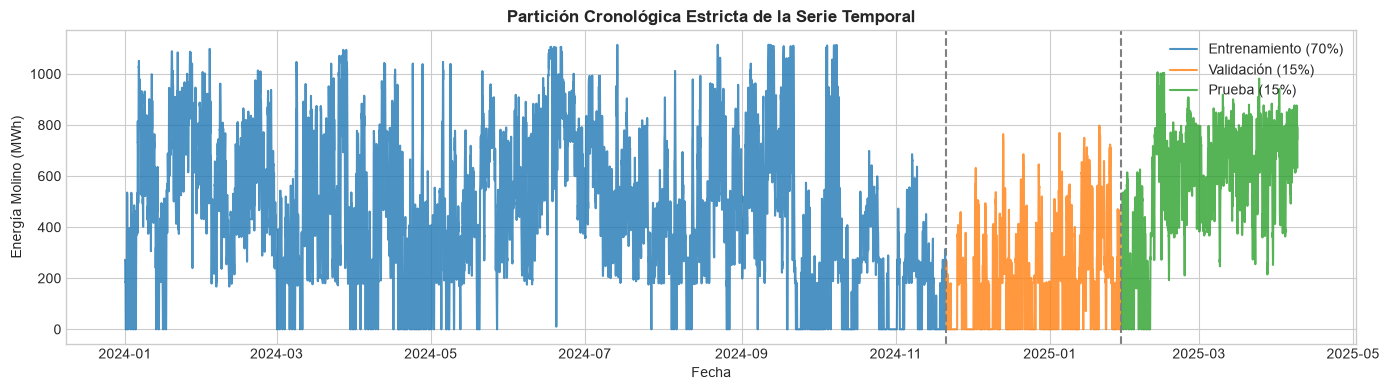

In [9]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print(f"Train : {train_df['Timestamp'].min()} a {train_df['Timestamp'].max()} ({len(train_df)} registros, {len(train_df)/n*100:.1f}%)")
print(f"Val   : {val_df['Timestamp'].min()} a {val_df['Timestamp'].max()} ({len(val_df)} registros, {len(val_df)/n*100:.1f}%)")
print(f"Test  : {test_df['Timestamp'].min()} a {test_df['Timestamp'].max()} ({len(test_df)} registros, {len(test_df)/n*100:.1f}%)")

# Gráfica de partición temporal
plt.figure(figsize=(14, 4))
plt.plot(train_df['Timestamp'], train_df[TARGET], label='Entrenamiento (70%)', color='#1f77b4', alpha=0.8)
plt.plot(val_df['Timestamp'], val_df[TARGET], label='Validación (15%)', color='#ff7f0e', alpha=0.8)
plt.plot(test_df['Timestamp'], test_df[TARGET], label='Prueba (15%)', color='#2ca02c', alpha=0.8)
plt.axvline(train_df['Timestamp'].iloc[-1], color='gray', linestyle='--')
plt.axvline(val_df['Timestamp'].iloc[-1], color='gray', linestyle='--')
plt.title('Partición Cronológica Estricta de la Serie Temporal', fontweight='bold')
plt.ylabel('Energía Molino (MWh)')
plt.xlabel('Fecha')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


## 6. Escalamiento de Datos y Ventanas Deslizantes (*Sliding Windows*)
1. **Normalización:** Se aplica `MinMaxScaler([0, 1])` ajustado **exclusivamente** sobre el conjunto de entrenamiento (`train_df`).
2. **Escalador Objetivo:** Se define un escalador separado para la variable objetivo `scaler_y` para permitir la inversión exacta de las predicciones a $\text{MWh}$.
3. **Formulación de Ventanas:**
   * **Lookback ($T_{\text{in}}$):** 72 horas (3 días previos de contexto multivariable).
   * **Horizon ($T_{\text{out}}$):** 24 horas (pronóstico *Day-Ahead* de las 24 horas consecutivas del día siguiente).
   * Tensores resultantes: $X \in \mathbb{R}^{N \times 72 \times 12}$ e $y \in \mathbb{R}^{N \times 24}$.


In [10]:
# Ajuste de escaladores únicamente sobre Train
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

scaler_x.fit(train_df[FEATURE_COLS])
scaler_y.fit(train_df[[TARGET]])

X_train_scaled = scaler_x.transform(train_df[FEATURE_COLS])
y_train_scaled = scaler_y.transform(train_df[[TARGET]])

X_val_scaled = scaler_x.transform(val_df[FEATURE_COLS])
y_val_scaled = scaler_y.transform(val_df[[TARGET]])

X_test_scaled = scaler_x.transform(test_df[FEATURE_COLS])
y_test_scaled = scaler_y.transform(test_df[[TARGET]])

def create_multistep_sequences(features, target, lookback=72, horizon=24):
    X, y = [], []
    for i in range(len(features) - lookback - horizon + 1):
        X.append(features[i:(i + lookback)])
        y.append(target[(i + lookback):(i + lookback + horizon), 0])
    return np.array(X), np.array(y)

LOOKBACK = 72
HORIZON = 24

X_train_seq, y_train_seq = create_multistep_sequences(X_train_scaled, y_train_scaled, LOOKBACK, HORIZON)
X_val_seq, y_val_seq = create_multistep_sequences(X_val_scaled, y_val_scaled, LOOKBACK, HORIZON)
X_test_seq, y_test_seq = create_multistep_sequences(X_test_scaled, y_test_scaled, LOOKBACK, HORIZON)

print(f"Dimensiones de secuencias de entrada (X):")
print(f"Train: {X_train_seq.shape} -> (Muestras, Pasos_Previos, Variables)")
print(f"Val  : {X_val_seq.shape}")
print(f"Test : {X_test_seq.shape}")
print(f"\nDimensiones de salida (y):")
print(f"Train: {y_train_seq.shape} -> (Muestras, Horizonte_24h)")


Dimensiones de secuencias de entrada (X):
Train: (7700, 72, 12) -> (Muestras, Pasos_Previos, Variables)
Val  : (1575, 72, 12)
Test : (1576, 72, 12)

Dimensiones de salida (y):
Train: (7700, 24) -> (Muestras, Horizonte_24h)


### Verificación de ausencia de data leakage
Se hacen tres comprobaciones en el código:
1. **Frontera temporal:** el último timestamp de entrenamiento es anterior al primero de validación, y el último de validación al primero de prueba (`assert`).
2. **Escalador:** los mínimos y máximos del `MinMaxScaler` coinciden con los de `train_df` (`assert`).
3. **Ventanas:** la primera ventana de entrenamiento usa las filas 0 a 71 como entrada y las filas 72 a 95 como objetivo, por lo que la entrada no contiene valores del periodo que se predice (`assert`).


In [11]:
# Verificaciones formales de no-leakage
assert train_df["Timestamp"].max() < val_df["Timestamp"].min(), "Error: Solapamiento temporal Train-Val"
assert val_df["Timestamp"].max() < test_df["Timestamp"].min(), "Error: Solapamiento temporal Val-Test"

# Comprobación de parámetros de escalamiento
check_min = np.allclose(scaler_x.data_min_, train_df[FEATURE_COLS].min().values)
check_max = np.allclose(scaler_x.data_max_, train_df[FEATURE_COLS].max().values)
assert check_min and check_max, "Error: El escalador fue ajustado con datos fuera de Train"

# Validación 3: la primera ventana usa filas 0-71 como entrada y 72-95 como objetivo
assert np.allclose(X_train_seq[0], X_train_scaled[0:LOOKBACK]), "Error: entrada desalineada"
assert np.allclose(y_train_seq[0], y_train_scaled[LOOKBACK:LOOKBACK + HORIZON, 0]), "Error: objetivo desalineado"

print("✓ Validación 1: Frontera temporal continua y disjunta (Sin solapamiento).")
print(f"  Train Fin: {train_df['Timestamp'].max()}  |  Val Inicio: {val_df['Timestamp'].min()}")
print(f"  Val Fin:   {val_df['Timestamp'].max()}  |  Test Inicio: {test_df['Timestamp'].min()}")
print("✓ Validación 2: Parámetros del MinMaxScaler ajustados al 100% solo sobre Train.")
print(f"✓ Validación 3: Ventanas causales: Entradas X en [t-72h, t-1h] -> Objetivo y en [t, t+23h].")


✓ Validación 1: Frontera temporal continua y disjunta (Sin solapamiento).
  Train Fin: 2024-11-20 19:00:00  |  Val Inicio: 2024-11-20 20:00:00
  Val Fin:   2025-01-29 09:00:00  |  Test Inicio: 2025-01-29 10:00:00
✓ Validación 2: Parámetros del MinMaxScaler ajustados al 100% solo sobre Train.
✓ Validación 3: Ventanas causales: Entradas X en [t-72h, t-1h] -> Objetivo y en [t, t+23h].


## 7. Modelado con Redes Neuronales Recurrentes (LSTM)
Se construyen y contrastan dos variantes arquitectónicas de redes LSTM:

* **Modelo 1 (Single LSTM):** 1 capa LSTM de 64 unidades con regularización por Dropout (20%) + capa Dense oculta (32 unidades, ReLU) + capa densa lineal de 24 unidades de salida.
* **Modelo 2 (Stacked LSTM):** 2 capas LSTM apiladas (Capa 1: 64 unidades con `return_sequences=True` + Dropout 20%; Capa 2: 32 unidades con `return_sequences=False` + Dropout 20%) + capa Dense oculta (32 unidades, ReLU) + salida lineal de 24 unidades.

**Función de Pérdida:** Pérdida Huber (robusta ante fluctuaciones abruptas de despacho).  
**Optimizador:** Adam ($lr = 0.001$).  
**Callbacks:** `EarlyStopping` restaurando los mejores pesos según `val_loss` y `ReduceLROnPlateau` con factor de reducción de $0.5$.


In [12]:
def build_single_lstm(input_shape, horizon=24):
    model = Sequential([
        LSTM(64, input_shape=input_shape, return_sequences=False),
        Dropout(0.20),
        Dense(32, activation='relu'),
        Dense(horizon)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss=tf.keras.losses.Huber(),
                  metrics=['mae'])
    return model

def build_stacked_lstm(input_shape, horizon=24):
    model = Sequential([
        LSTM(64, input_shape=input_shape, return_sequences=True),
        Dropout(0.20),
        LSTM(32, return_sequences=False),
        Dropout(0.20),
        Dense(32, activation='relu'),
        Dense(horizon)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss=tf.keras.losses.Huber(),
                  metrics=['mae'])
    return model

input_shape = (LOOKBACK, len(FEATURE_COLS))

model_single_lstm = build_single_lstm(input_shape, HORIZON)
model_stacked_lstm = build_stacked_lstm(input_shape, HORIZON)

print("=== Arquitectura Modelo 1: Single LSTM ===")
model_single_lstm.summary()
print("\n=== Arquitectura Modelo 2: Stacked LSTM ===")
model_stacked_lstm.summary()


=== Arquitectura Modelo 1: Single LSTM ===


/Users/jcoronelc/Documents/MIA/neural-networks/activities/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,584 (88.22 KB)

 Trainable params: 22,584 (88.22 KB)

... (3 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 72, 64)         │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 72, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,976 (132.72 KB)

 Trainable params: 33,976 (132.72 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Entrenamiento de los Modelos y Curvas de Aprendizaje


In [13]:
EPOCHS = 40
BATCH_SIZE = 64

callbacks_single = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1)
]

callbacks_stacked = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1)
]

print("--- Entrenando Modelo 1: Single LSTM ---")
history_single = model_single_lstm.fit(
    X_train_seq, y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_single,
    verbose=1
)

print("\n--- Entrenando Modelo 2: Stacked LSTM ---")
history_stacked = model_stacked_lstm.fit(
    X_train_seq, y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_stacked,
    verbose=1
)


--- Entrenando Modelo 1: Single LSTM ---
Epoch 1/40
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0406 - mae: 0.2154 - val_loss: 0.0146 - val_mae: 0.1396 - learning_rate: 0.0010
Epoch 2/40
121/121 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0178 - mae: 0.1469 - val_loss: 0.0126 - val_mae: 0.1278 - learning_rate: 0.0010
Epoch 3/40
121/121 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0152 - mae: 0.1342 - val_loss: 0.0128 - val_mae: 0.1285 - learning_rate: 0.0010
Epoch 4/40
121/121 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0142 - mae: 0.1291 - val_loss: 0.0131 - val_mae: 0.1297 - learning_rate: 0.0010
Epoch 5/40
121/121 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0136 - mae: 0.1261 - val_loss: 0.0129 - val_mae: 0.1280 - learning_rate: 0.0010
Epoch 6/40
116/121 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0131 - mae: 0.1237
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
121/121 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0131 - mae: 0.1237 - val_loss: 0.0

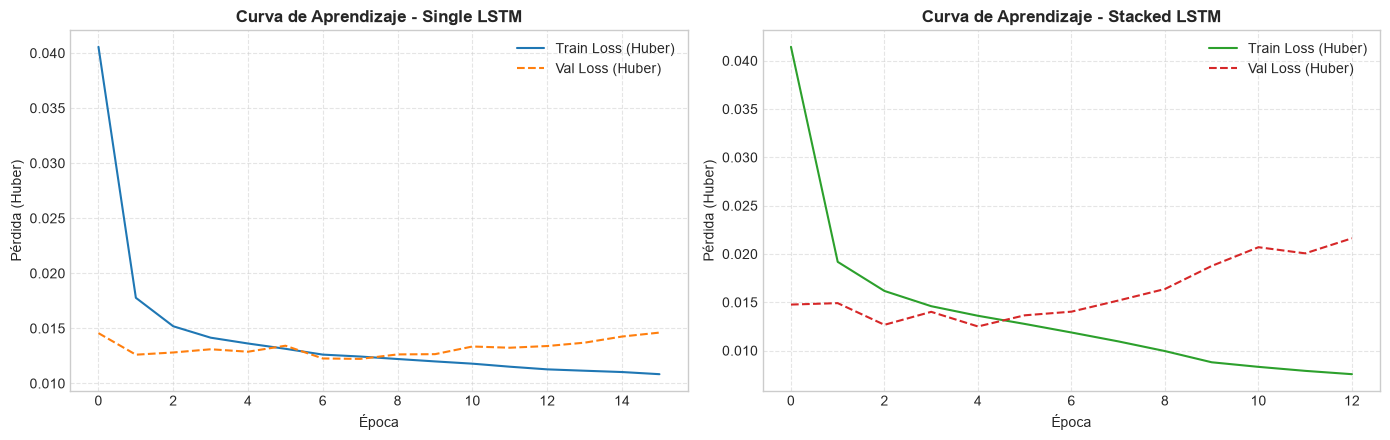

In [14]:
# Comparación de Curvas de Aprendizaje (Pérdida de Entrenamiento vs Validación)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(history_single.history['loss'], label='Train Loss (Huber)', color='#1f77b4')
ax1.plot(history_single.history['val_loss'], label='Val Loss (Huber)', color='#ff7f0e', linestyle='--')
ax1.set_title('Curva de Aprendizaje - Single LSTM', fontweight='bold')
ax1.set_xlabel('Época')
ax1.set_ylabel('Pérdida (Huber)')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(history_stacked.history['loss'], label='Train Loss (Huber)', color='#2ca02c')
ax2.plot(history_stacked.history['val_loss'], label='Val Loss (Huber)', color='#d62728', linestyle='--')
ax2.set_title('Curva de Aprendizaje - Stacked LSTM', fontweight='bold')
ax2.set_xlabel('Época')
ax2.set_ylabel('Pérdida (Huber)')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 9. Evaluación de Rendimiento sobre el Conjunto de Prueba
Se obtienen las predicciones sobre el conjunto de test, se invierte el escalado a $\text{MWh}$ y se evalúan las métricas formales:
* **RMSE (Root Mean Squared Error):** Penalización cuadrática para evaluar precisión en crestas de demanda.
* **MAE (Mean Absolute Error):** Error lineal medio en magnitud de potencia.
* **MAPE (Mean Absolute Percentage Error):** Error porcentual relativo sobre valores reales $> 1\text{ MWh}$.
* **$R^2$ Score:** Coeficiente de determinación sobre la serie real.


In [15]:
# Predicciones normalizadas en test
y_pred_single_scaled = model_single_lstm.predict(X_test_seq)
y_pred_stacked_scaled = model_stacked_lstm.predict(X_test_seq)

# Inversión de escala al rango original de MWh
def inverse_multistep(y_scaled, scaler):
    original_shape = y_scaled.shape
    flattened = y_scaled.reshape(-1, 1)
    inv_flattened = scaler.inverse_transform(flattened)
    return inv_flattened.reshape(original_shape)

y_test_real = inverse_multistep(y_test_seq, scaler_y)
y_pred_single_real = inverse_multistep(y_pred_single_scaled, scaler_y)
y_pred_stacked_real = inverse_multistep(y_pred_stacked_scaled, scaler_y)

# Función de métricas globales extraídas directamente de los arreglos numéricos
def calcular_metricas(y_true, y_pred):
    y_t_flat = y_true.flatten()
    y_p_flat = y_pred.flatten()

    rmse = np.sqrt(mean_squared_error(y_t_flat, y_p_flat))
    mae = mean_absolute_error(y_t_flat, y_p_flat)

    # Filtro de umbral menor para evitar indeterminaciones en MAPE
    mask = y_t_flat > 1.0
    mape = np.mean(np.abs((y_t_flat[mask] - y_p_flat[mask]) / y_t_flat[mask])) * 100
    r2 = r2_score(y_t_flat, y_p_flat)

    return {'RMSE (MWh)': rmse, 'MAE (MWh)': mae, 'MAPE (%)': mape, 'R2': r2}

metricas_single = calcular_metricas(y_test_real, y_pred_single_real)
metricas_stacked = calcular_metricas(y_test_real, y_pred_stacked_real)

df_metricas = pd.DataFrame([metricas_single, metricas_stacked], index=['Single LSTM', 'Stacked LSTM'])
df_metricas.round(3)


50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


,RMSE (MWh),MAE (MWh),MAPE (%),R2
Single LSTM,154.365,123.552,24.428,0.47
Stacked LSTM,164.240,128.471,25.939,0.40


## 10. Visualización de Pronósticos y Análisis de Residuos
Comparación gráfica del perfil horario proyectado a 24 horas vista frente al despacho real en ventanas del conjunto de prueba.


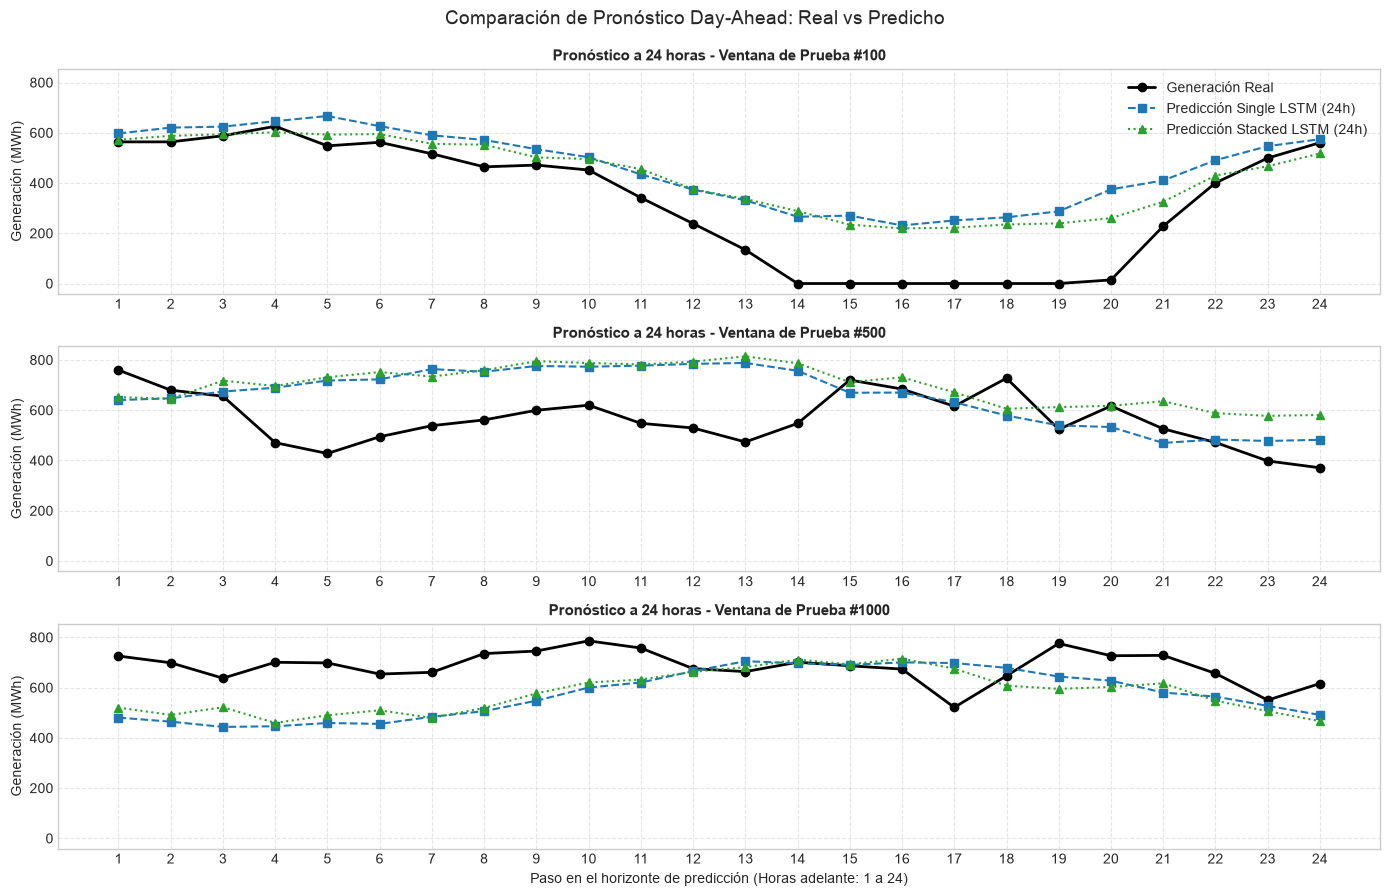

In [16]:
# Selección de 3 ventanas representativas de prueba
indices_ejemplos = [100, 500, 1000]

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharey=True)

for i, idx in enumerate(indices_ejemplos):
    ax = axes[i]
    horas_horizonte = np.arange(1, HORIZON + 1)

    ax.plot(horas_horizonte, y_test_real[idx], label='Generación Real', color='black', linewidth=2, marker='o')
    ax.plot(horas_horizonte, y_pred_single_real[idx], label='Predicción Single LSTM (24h)', color='#1f77b4', linestyle='--', marker='s')
    ax.plot(horas_horizonte, y_pred_stacked_real[idx], label='Predicción Stacked LSTM (24h)', color='#2ca02c', linestyle=':', marker='^')

    ax.set_title(f'Pronóstico a 24 horas - Ventana de Prueba #{idx}', fontweight='bold', fontsize=11)
    ax.set_ylabel('Generación (MWh)')
    ax.set_xticks(horas_horizonte)
    ax.grid(True, linestyle='--', alpha=0.5)
    if i == 0:
        ax.legend(loc='upper right')

axes[-1].set_xlabel('Paso en el horizonte de predicción (Horas adelante: 1 a 24)')
plt.suptitle('Comparación de Pronóstico Day-Ahead: Real vs Predicho', fontsize=14, y=0.99)
plt.tight_layout()
plt.show()


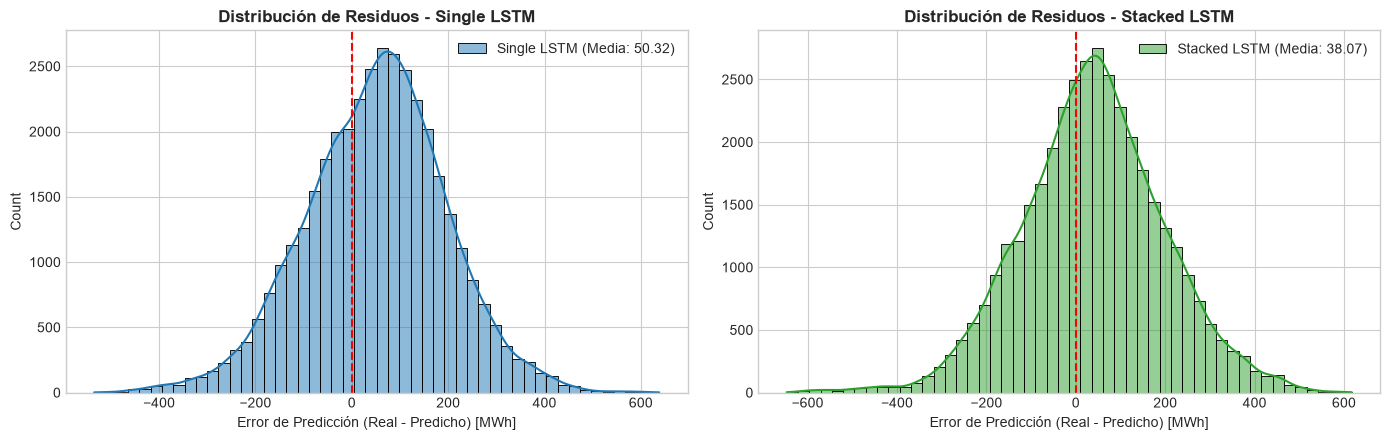

In [17]:
# Análisis de Residuos (Distribución del error Real - Predicho)
residuos_single = (y_test_real - y_pred_single_real).flatten()
residuos_stacked = (y_test_real - y_pred_stacked_real).flatten()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(residuos_single, bins=50, kde=True, ax=ax1, color='#1f77b4', label=f'Single LSTM (Media: {np.mean(residuos_single):.2f})')
sns.histplot(residuos_stacked, bins=50, kde=True, ax=ax2, color='#2ca02c', label=f'Stacked LSTM (Media: {np.mean(residuos_stacked):.2f})')

ax1.axvline(0, color='red', linestyle='--')
ax1.set_title('Distribución de Residuos - Single LSTM', fontweight='bold')
ax1.set_xlabel('Error de Predicción (Real - Predicho) [MWh]')
ax1.legend()

ax2.axvline(0, color='red', linestyle='--')
ax2.set_title('Distribución de Residuos - Stacked LSTM', fontweight='bold')
ax2.set_xlabel('Error de Predicción (Real - Predicho) [MWh]')
ax2.legend()

plt.tight_layout()
plt.show()


## 11. Modelos de referencia (baselines) y MASE

Antes de concluir que el LSTM es "bueno", lo compararamos contra **métodos muy simples**. Si una regla trivial rinde igual o mejor, la complejidad de la red no se justifica.

Baselines usados (todos con las mismas ventanas de test):
* **Persistencia:** repetir el último valor observado durante las 24 h.
* **Naive 24 h:** "mañana será igual que ayer" (misma hora del día anterior).
* **Naive 168 h:** "igual que la misma hora de la semana pasada".
* **Promedio 3 días:** promedio de la misma hora en los 3 días previos de la ventana.
* **Ridge:** regresión lineal regularizada sobre toda la ventana (72 h × 12 variables).

**MASE** (*Mean Absolute Scaled Error*) = MAE del modelo / MAE del naive 24 h calculado sobre *train*.
Si MASE < 1, el modelo supera a "repetir ayer" (medido en train); si MASE > 1, es peor.

In [18]:
from sklearn.linear_model import Ridge

serie = df[TARGET].values
n_win = len(y_test_real)

# Índices globales (en df) de las horas objetivo de cada ventana de test
idx_obj = val_end + LOOKBACK + np.arange(n_win)[:, None] + np.arange(HORIZON)[None, :]
assert np.allclose(serie[idx_obj], y_test_real, atol=1e-3), "Desalineación entre ventanas y serie original"

preds = {}

# 1) Persistencia: último valor de la ventana repetido 24 veces
ultimo = inverse_multistep(X_test_seq[:, -1:, 0], scaler_y)          # columna 0 = Energía_Molino
preds['Persistencia'] = np.repeat(ultimo, HORIZON, axis=1)

# 2) Naive 24 h: las últimas 24 h de la ventana son el pronóstico de las próximas 24 h
preds['Naive 24h (ayer)'] = inverse_multistep(X_test_seq[:, -24:, 0], scaler_y)

# 3) Naive 168 h: misma hora de la semana pasada (se toma de la serie completa)
preds['Naive 168h (sem. pasada)'] = serie[idx_obj - 168]

# 4) Promedio de la misma hora en los últimos 3 días de la ventana
bloques = X_test_seq[:, :, 0].reshape(n_win, LOOKBACK // 24, 24)
preds['Promedio 3 días'] = inverse_multistep(bloques.mean(axis=1), scaler_y)

# 5) Ridge sobre la ventana aplanada
ridge = Ridge(alpha=10.0).fit(X_train_seq.reshape(len(X_train_seq), -1), y_train_seq)
preds['Ridge'] = inverse_multistep(ridge.predict(X_test_seq.reshape(n_win, -1)), scaler_y)

# 6) Los modelos LSTM ya entrenados
preds['Single LSTM'] = y_pred_single_real
preds['Stacked LSTM'] = y_pred_stacked_real

# Escala del MASE: MAE del naive 24 h en train
y_tr = train_df[TARGET].values
esc_mase = np.mean(np.abs(y_tr[24:] - y_tr[:-24]))

filas = {}
for nombre, p in preds.items():
    m = calcular_metricas(y_test_real, p)
    m['MASE'] = m['MAE (MWh)'] / esc_mase
    filas[nombre] = m
df_comp = pd.DataFrame(filas).T.round(3).sort_values('RMSE (MWh)')
df_comp

,RMSE (MWh),MAE (MWh),MAPE (%),R2,MASE
Ridge,137.200,105.420,22.095,0.581,0.669
Single LSTM,154.365,123.552,24.428,0.470,0.784
Stacked LSTM,164.240,128.471,25.939,0.400,0.816
Promedio 3 días,168.232,125.804,26.380,0.370,0.799
Naive 24h (ayer),169.306,120.912,25.535,0.362,0.768
Persistencia,203.053,154.842,33.496,0.083,0.983
Naive 168h (sem. pasada),223.503,159.069,30.995,-0.111,1.010


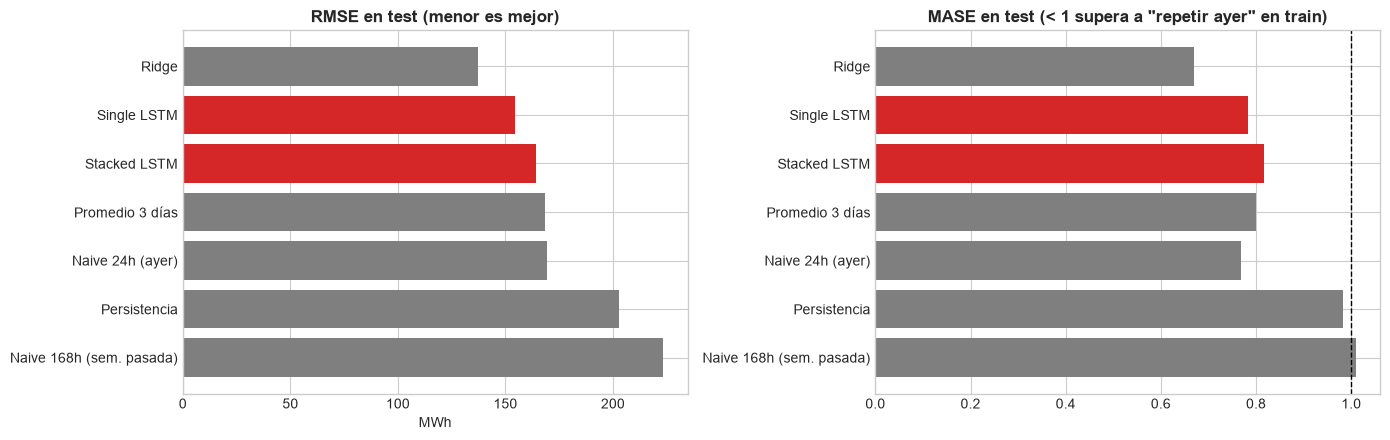

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
orden = df_comp.index[::-1]
colores = ['#d62728' if 'LSTM' in n else '#7f7f7f' for n in orden]

ax1.barh(orden, df_comp.loc[orden, 'RMSE (MWh)'], color=colores)
ax1.set_title('RMSE en test (menor es mejor)', fontweight='bold'); ax1.set_xlabel('MWh')

ax2.barh(orden, df_comp.loc[orden, 'MASE'], color=colores)
ax2.axvline(1, color='black', linestyle='--', linewidth=1)
ax2.set_title('MASE en test (< 1 supera a "repetir ayer" en train)', fontweight='bold')

plt.tight_layout(); plt.show()

#### Análisis de resultados

**1. El mejor modelo es Ridge (lineal regularizado):**
Con RMSE de 137.20 MWh, MAE de 105.42 MWh, $R^2$ de 0.581 y MASE de 0.669, el modelo Ridge supera con claridad a las redes recurrentes (mejora al Single LSTM en 17.17 MWh de RMSE y en 18.13 MWh de MAE). Esto demuestra que una combinación lineal de las observaciones previas y las variables cíclicas capta la dinámica principal sin incurrir en el desajuste de optimización que sufren las redes complejas.

**2. Single LSTM frente a la referencia Naive 24 h:**
El Single LSTM reduce el RMSE en un 8.8% respecto a repetir el día anterior (154.37 frente a 169.31 MWh), lo que indica que amortigua mejor desviaciones cuadráticas grandes. Sin embargo, en error absoluto medio (MAE), el Naive 24 h resulta ligeramente superior (120.91 frente a 123.55 MWh), reflejado también en un mejor MASE (0.768 vs 0.784). En términos prácticos, predecir con una regla fija de "repetir la misma hora de ayer" entrega un error mediano comparable o menor al de la red recurrente.

**3. Single LSTM frente a Stacked LSTM:**
El Single LSTM supera al Stacked en todas las métricas en test: RMSE (154.37 vs 164.24 MWh), MAE (123.55 vs 128.47 MWh) y $R^2$ (0.470 vs 0.400). El Stacked LSTM (33,976 parámetros) experimentó sobreajuste temprano, deteniendo su entrenamiento en la época 13 y restaurando los pesos de la época 5, sin lograr ventaja frente a la arquitectura más simple de una sola capa.

**Conclusión:** Las LSTM no logran batir a una regresión lineal regularizada (Ridge) y apenas compiten con el pronóstico ingenuo diario en este conjunto de datos.


## 12. ¿Cambió el régimen entre train y test?

El EDA mostró un estiaje fuerte (sep–nov 2024) con generación cercana a 0. Si ese periodo cae casi todo en *train* y el *test* tiene otra condición hidrológica, parte del error puede deberse a un **cambio de régimen** y no a una limitación del modelo.

,Media (MWh),Desv. est. (MWh),% horas con ~0 MWh,Unidades Molino (prom.)
Train,473.05,295.26,11.21,6.67
Val,203.19,205.80,36.71,3.19
Test,575.05,224.25,5.09,7.69


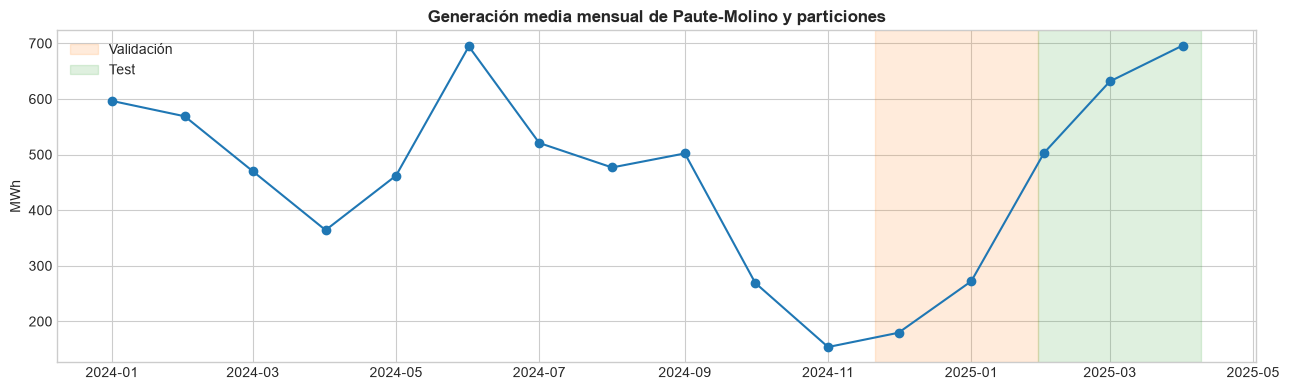

In [20]:
particiones = {'Train': train_df, 'Val': val_df, 'Test': test_df}
resumen = pd.DataFrame({
    nombre: {
        'Media (MWh)': d[TARGET].mean(),
        'Desv. est. (MWh)': d[TARGET].std(),
        '% horas con ~0 MWh': (d[TARGET] < 1).mean() * 100,
        'Unidades Molino (prom.)': d['Unidades_Molino'].mean(),
    } for nombre, d in particiones.items()
}).T.round(2)
display(resumen)

mensual = df.set_index('Timestamp')[TARGET].resample('MS').mean()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(mensual.index, mensual.values, marker='o', color='#1f77b4')
ax.axvspan(val_df['Timestamp'].min(), val_df['Timestamp'].max(), color='#ff7f0e', alpha=0.15, label='Validación')
ax.axvspan(test_df['Timestamp'].min(), test_df['Timestamp'].max(), color='#2ca02c', alpha=0.15, label='Test')
ax.set_title('Generación media mensual de Paute-Molino y particiones', fontweight='bold')
ax.set_ylabel('MWh'); ax.legend()
plt.tight_layout(); plt.show()

In [21]:
# Error en test desglosado por mes (MAE por ventana, agrupado por el mes de su primera hora objetivo)
ts_obj = pd.to_datetime(test_df['Timestamp'].iloc[LOOKBACK:LOOKBACK + n_win].values)
mes = ts_obj.to_period('M')

mae_ventana = pd.DataFrame({
    nombre: np.abs(y_test_real - preds[nombre]).mean(axis=1)
    for nombre in ['Naive 24h (ayer)', 'Ridge', 'Single LSTM', 'Stacked LSTM']
})
tabla_mes = mae_ventana.groupby(mes).mean().round(1)
tabla_mes.insert(0, 'N ventanas', mae_ventana.groupby(mes).size())
tabla_mes.index.name = 'Mes'
tabla_mes

,N ventanas,Naive 24h (ayer),Ridge,Single LSTM,Stacked LSTM
Mes,,,,,
2025-02,662,137.2,115.2,127.8,129.0
2025-03,744,112.0,99.1,117.6,124.2
2025-04,170,96.7,94.9,133.3,145.2


#### Análisis de resultados

**1. Disparidad en las condiciones operativas por partición:**

| Partición | Media (MWh) | Desv. Est. (MWh) | % horas ~0 MWh | Unidades Molino (prom.) |
|---|---|---|---|---|
| Train | 473.05 | 295.26 | 11.21% | 6.67 |
| Validación | 203.19 | 205.80 | 36.71% | 3.19 |
| Test | 575.05 | 224.25 | 5.09% | 7.69 |

La partición de validación concentra el punto crítico del estiaje ecuatoriano (noviembre 2024 - enero 2025), con una media un 57% menor a la de entrenamiento y más de un tercio de las horas en generación nula. En contraste, el conjunto de prueba evalúa la recuperación hidrológica (febrero - abril 2025), donde Molino opera con una media de 575 MWh y apenas un 5% de ceros. Los criterios de parada temprana seleccionaron los pesos de las redes evaluando un comportamiento de crisis que no se asemeja al régimen que debieron pronosticar en test.

**2. Error en test desglosado por mes (MAE en MWh):**

| Mes | N ventanas | Naive 24 h | Ridge | Single LSTM | Stacked LSTM |
|---|---|---|---|---|---|
| Feb 2025 | 662 | 137.2 | 115.2 | 127.8 | 129.0 |
| Mar 2025 | 744 | 112.0 | 99.1 | 117.6 | 124.2 |
| Abr 2025 | 170 | 96.7 | 94.9 | 133.3 | 145.2 |

* Ridge sostiene el menor error en los tres meses evaluados.
* En febrero, mes de transición tras el estiaje, las LSTM logran una ventaja sobre el Naive (127.8 vs 137.2 MWh).
* En marzo y abril, conforme la central entra en un régimen continuo de alta producción, el error del Naive 24 h se reduce sustancialmente (de 137.2 a 96.7 MWh), mientras que el error de las redes LSTM aumenta (Single sube a 133.3 MWh y Stacked a 145.2 MWh en abril). La red arrastra sesgo de los periodos anteriores y no se acopla a la estabilidad de la cota alta con la misma rapidez que las referencias simples.

**Conclusión:** El rendimiento de los modelos depende fuertemente del régimen hidrológico del periodo evaluado, lo que invalida conclusiones basadas en una única partición fija.


## 13. Validación *walk-forward* (versión simplificada)

Una sola partición train/val/test depende mucho de **qué periodo** cayó en el test. En *walk-forward* se repite el experimento varias veces con **origen móvil**: el entrenamiento crece y el test avanza, siempre respetando el orden cronológico.

Aquí usamos 4 pliegues de ~2 meses de test cada uno, el Single LSTM (15 épocas máx., con *early stopping*) y lo comparamos contra el naive 24 h.
No es una búsqueda exhaustiva: el objetivo es ver **si la conclusión cambia según el periodo**.

In [22]:
def walk_forward(df, n_folds=4, test_frac=0.12, epochs=15):
    n = len(df)
    test_size = int(n * test_frac)          # ~1,300 h ≈ 2 meses
    filas = []
    for k in range(n_folds):
        test_end = n - (n_folds - 1 - k) * test_size
        test_start = test_end - test_size
        tr = df.iloc[:test_start]                       # entrenamiento: todo lo anterior
        te = df.iloc[test_start - LOOKBACK:test_end]    # test + contexto previo (solo como entrada)

        # Escaladores ajustados solo con el train de este pliegue
        sx = MinMaxScaler().fit(tr[FEATURE_COLS])
        sy = MinMaxScaler().fit(tr[[TARGET]])
        Xtr, ytr = create_multistep_sequences(sx.transform(tr[FEATURE_COLS]), sy.transform(tr[[TARGET]]), LOOKBACK, HORIZON)
        Xte, yte = create_multistep_sequences(sx.transform(te[FEATURE_COLS]), sy.transform(te[[TARGET]]), LOOKBACK, HORIZON)

        tf.keras.utils.set_random_seed(SEED)
        modelo = build_single_lstm((LOOKBACK, len(FEATURE_COLS)), HORIZON)
        modelo.fit(Xtr, ytr, validation_split=0.1, epochs=epochs, batch_size=BATCH_SIZE, verbose=0,
                   callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)])

        y_real = inverse_multistep(yte, sy)
        p_lstm = inverse_multistep(modelo.predict(Xte, verbose=0), sy)
        p_naive = inverse_multistep(Xte[:, -24:, 0], sy)   # col 0 = target: mismos parámetros que sy

        y_tr_k = tr[TARGET].values
        esc = np.mean(np.abs(y_tr_k[24:] - y_tr_k[:-24]))
        mae_lstm = mean_absolute_error(y_real.flatten(), p_lstm.flatten())
        mae_naive = mean_absolute_error(y_real.flatten(), p_naive.flatten())

        filas.append({
            'Pliegue': k + 1,
            'Test desde': te['Timestamp'].iloc[LOOKBACK].date(),
            'Test hasta': te['Timestamp'].iloc[-1].date(),
            'Horas train': len(tr),
            '% horas ~0 MWh (test)': round((te[TARGET].iloc[LOOKBACK:] < 1).mean() * 100, 1),
            'MAE LSTM': mae_lstm,
            'MAE Naive 24h': mae_naive,
            'MASE LSTM': mae_lstm / esc,
            'MASE Naive 24h': mae_naive / esc,
        })
        print(f"Pliegue {k+1}/{n_folds} listo")
    return pd.DataFrame(filas).round(3)

df_wf = walk_forward(df)
df_wf

/Users/jcoronelc/Documents/MIA/neural-networks/activities/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Pliegue 1/4 listo


/Users/jcoronelc/Documents/MIA/neural-networks/activities/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Pliegue 2/4 listo


/Users/jcoronelc/Documents/MIA/neural-networks/activities/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Pliegue 3/4 listo


/Users/jcoronelc/Documents/MIA/neural-networks/activities/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Pliegue 4/4 listo


,Pliegue,Test desde,Test hasta,Horas train,% horas ~0 MWh (test),MAE LSTM,MAE Naive 24h,MASE LSTM,MASE Naive 24h
0,1,2024-08-29,2024-10-24,5792,18.7,168.521,159.357,1.038,0.982
1,2,2024-10-24,2024-12-18,7128,45.0,152.926,124.920,0.947,0.773
2,3,2024-12-18,2025-02-12,8464,28.7,137.794,152.453,0.885,0.980
3,4,2025-02-12,2025-04-09,9800,0.0,133.876,116.127,0.863,0.748


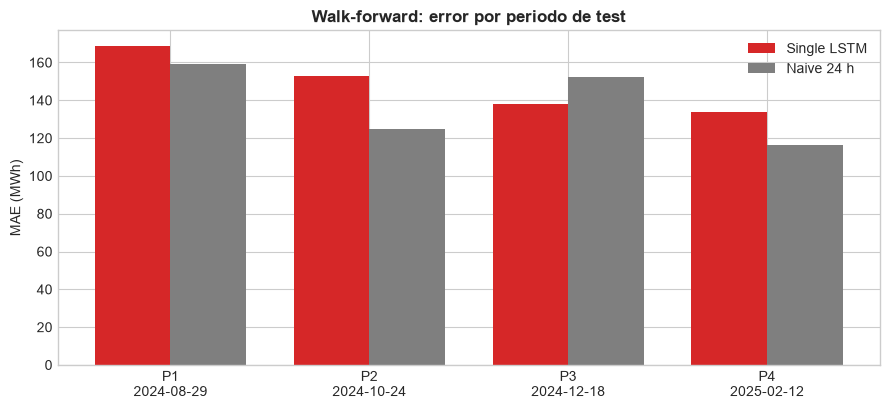

MAE LSTM promedio: 148.3 ± 15.8 MWh
MAE Naive 24h promedio: 138.2 ± 20.9 MWh


In [23]:
x = np.arange(len(df_wf)); w = 0.38
plt.figure(figsize=(9, 4.2))
plt.bar(x - w/2, df_wf['MAE LSTM'], w, label='Single LSTM', color='#d62728')
plt.bar(x + w/2, df_wf['MAE Naive 24h'], w, label='Naive 24 h', color='#7f7f7f')
plt.xticks(x, [f"P{p}\n{d}" for p, d in zip(df_wf['Pliegue'], df_wf['Test desde'])])
plt.ylabel('MAE (MWh)'); plt.title('Walk-forward: error por periodo de test', fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()

print(f"MAE LSTM promedio: {df_wf['MAE LSTM'].mean():.1f} ± {df_wf['MAE LSTM'].std():.1f} MWh")
print(f"MAE Naive 24h promedio: {df_wf['MAE Naive 24h'].mean():.1f} ± {df_wf['MAE Naive 24h'].std():.1f} MWh")

#### Análisis de resultados

| Pliegue | Periodo de test | % horas ~0 MWh | MAE LSTM | MAE Naive 24 h | Mejor modelo |
|---|---|---|---|---|---|
| 1 | 29-ago → 24-oct 2024 | 18.7% | 168.52 | 159.36 | Naive 24 h |
| 2 | 24-oct → 18-dic 2024 | 45.0% | 152.93 | 124.92 | Naive 24 h |
| 3 | 18-dic 2024 → 12-feb 2025 | 28.7% | 137.79 | 152.45 | Single LSTM |
| 4 | 12-feb → 09-abr 2025 | 0.0% | 133.88 | 116.13 | Naive 24 h |

**1. El Naive 24 h supera a la LSTM en 3 de los 4 pliegues temporales:**
Al evaluar sobre ventanas móviles a lo largo del tiempo, el promedio del MAE para el Naive 24 h es de 138.2 ± 20.9 MWh, frente a 148.3 ± 15.8 MWh de la red LSTM (el Naive resulta aproximadamente un 7% más preciso en media). La LSTM solo logra superar al Naive en el pliegue 3, que corresponde a la salida paulatina del estiaje más severo.

**2. Sensibilidad al régimen y transiciones:**
En los pliegues con regímenes hidrológicos extremos y sostenidos (pliegue 2 con 45% de horas apagadas o pliegue 4 con operación continua al 0% de ceros), la regla de repetir el día anterior es muy difícil de batir, ya que el sistema exhibe alta inercia. La red neuronal acumula mayor error intentando predecir variaciones donde la serie en realidad se mantiene constante.

**Conclusión:** La validación con origen móvil confirma que el aparente beneficio de las LSTM observado en particiones estáticas aisladas es circunstancial y no se sostiene de forma consistente a lo largo del tiempo.


## 14. Conclusiones, limitaciones y trabajo futuro

### Conclusiones
1. **Desempeño base en el conjunto de prueba:** En la partición fija de test (febrero–abril 2025), el modelo Single LSTM alcanzó un RMSE de 154.37 MWh, un MAE de 123.55 MWh y un $R^2$ de 0.470, superando al Stacked LSTM (RMSE 164.24 MWh, MAE 128.47 MWh y $R^2$ de 0.400). El incremento en profundidad del Stacked resultó contraproducente debido a un sobreajuste prematuro en la fase de validación.
2. **Superioridad de los modelos lineales y heurísticas simples:** La regresión Ridge superó ampliamente a ambas redes recurrentes en todas las métricas evaluadas (RMSE 137.20 MWh, MAE 105.42 MWh y $R^2$ 0.581). Asimismo, frente a la referencia Naive 24 h, aunque el Single LSTM obtuvo un RMSE menor (154.37 vs 169.31 MWh), el Naive presentó un error medio absoluto más bajo (120.91 vs 123.55 MWh) y mejor MASE (0.768 vs 0.784).
3. **Inconsistencia temporal evidenciada por *walk-forward*:** Al someter la metodología a 4 pliegues de validación con origen móvil, el pronóstico ingenuo diario superó al LSTM en 3 de los 4 periodos analizados (MAE medio de 138.2 MWh frente a 148.3 MWh de la red). La ventaja de la LSTM solo emergió puntualmente durante la transición de salida del estiaje.
4. **Impacto determinante del cambio de régimen operativo:** El estiaje severo de finales de 2024 provocó que el conjunto de validación tuviese una media de apenas 203 MWh (con 36.7% de horas en 0), mientras que el test evaluó un periodo de alta producción con 575 MWh de media (5% de ceros). Esta falta de representatividad entre particiones condiciona el ajuste de los hiperparámetros y la parada temprana.
5. **Balance metodológico:** El contraste sistemático contra métodos de referencia y la validación en múltiples ventanas temporales resultaron indispensables: sin ellos, los resultados del LSTM habrían sugerido una capacidad predictiva artificial que no se sostiene ante comparativas rigurosas.

### Limitaciones
* **Extensión del registro:** El dataset comprende 15 meses de operación continua, conteniendo una única temporada seca, lo que impide evaluar la estacionalidad interanual.
* **Ausencia de variables hidrológicas exógenas:** No se dispone de series de caudales afluentes, cotas de embalse de Mazar/Amaluza ni precipitaciones, factores físicos determinantes en la disponibilidad de agua para turbinar.
* **Desconocimiento del programa de despacho:** Las órdenes de despacho del operador nacional (CENACE) condicionan qué unidades se encienden o apagan por motivos ajenos a la serie histórica inmediata.
* **Tratamiento homogéneo de periodos en cero:** Los cortes de carga y racionamientos energéticos se procesan como variaciones normales de generación, sin un modelo explícito de estados operativos (encendido/apagado).

### Trabajo futuro
1. **Incorporación de variables hidrológicas:** Integrar niveles de embalse, aportes de cuenca y pronósticos meteorológicos de precipitación.
2. **Modelos híbridos de dos etapas:** Implementar una etapa de clasificación para pronosticar el estado de disponibilidad/apagado de la central y una etapa de regresión para estimar la potencia despachada cuando opera.
3. **Evaluación de arquitecturas alternativas:** Contrastar con redes GRU y modelos de árboles de decisión basados en gradiente (LightGBM/XGBoost) con retardos temporales explícitos.
4. **Experimentación con múltiples semillas:** Realizar entrenamientos repetidos bajo diferentes inicializaciones para cuantificar la variabilidad estadística de las métricas.
